# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

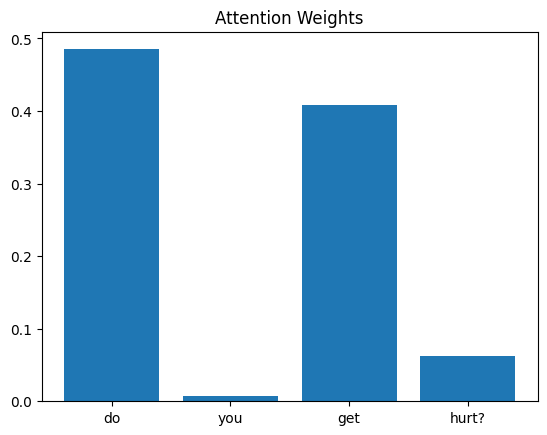

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

The words receiving the highest attention weights are generally important for understanding the question. For example, the model may focus on words such as "old" or "purpose" because they indicate what the question is asking. However, attention weights show where the model focuses, and do not necessarily represent the true importance of every word.


Question: do you get hurt?
Predicted answer group: 0
Highest attention word: do
Attention weight: 0.4851


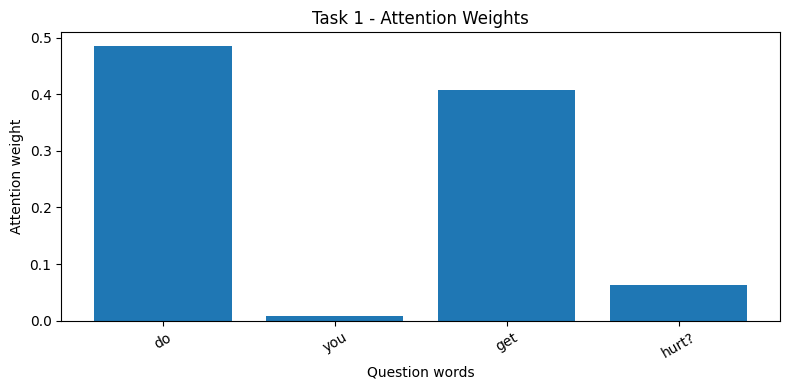

Question: are you old?
Predicted answer group: 3
Highest attention word: are
Attention weight: 0.6517


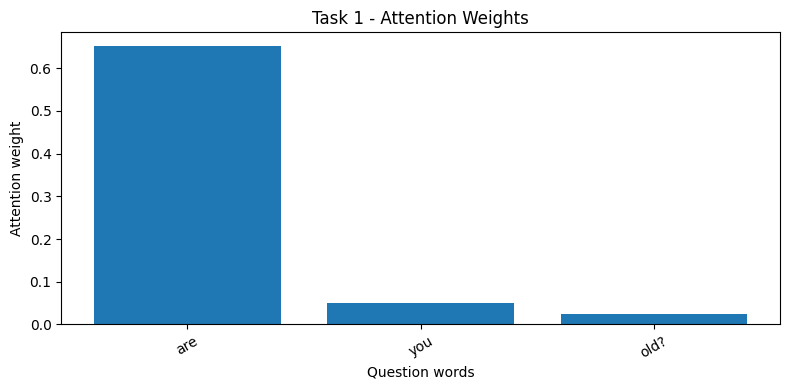

Question: what is your purpose?
Predicted answer group: 2
Highest attention word: is
Attention weight: 0.5954


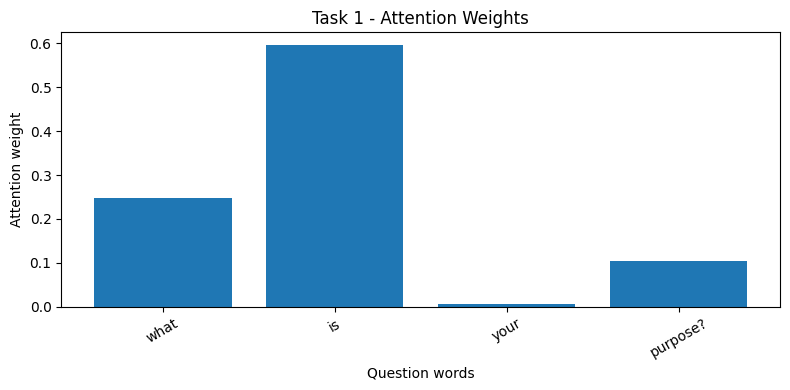

In [8]:
task1_indices = [0, 14, 70]

model.eval()

for idx in task1_indices:

    question = df["question"].iloc[idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    word_weights = weights[0, :len(words)].tolist()

    highest_index = word_weights.index(max(word_weights))

    print("Question:", question)

    print("Predicted answer group:", prediction.argmax(dim=1).item())

    print("Highest attention word:",
          words[highest_index])

    print("Attention weight:",
          round(word_weights[highest_index], 4))

    plt.figure(figsize=(8, 4))

    plt.bar(words, word_weights)

    plt.title("Task 1 - Attention Weights")

    plt.xlabel("Question words")

    plt.ylabel("Attention weight")

    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.show()

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

The model may focus on different words when processing these questions because their wording is different. This suggests that attention assigns weights to words based on their context and the patterns learned during training.

Question: how do you feel about artificial intelligence?
Predicted answer group: 2
Highest attention word: about
Attention weight: 0.8994


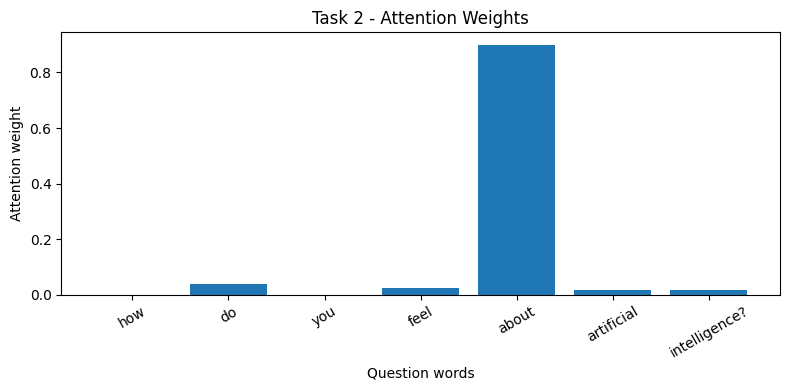

Question: what is your opinion about ai?
Predicted answer group: 2
Highest attention word: about
Attention weight: 0.8779


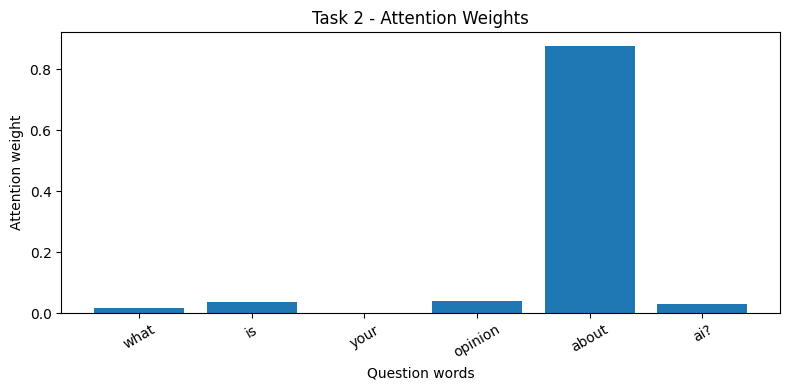

In [9]:
task2_indices = [126, 128]

model.eval()

for idx in task2_indices:

    question = df["question"].iloc[idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    word_weights = weights[0, :len(words)].tolist()

    highest_index = word_weights.index(max(word_weights))

    print("Question:", question)

    print("Predicted answer group:", prediction.argmax(dim=1).item())

    print("Highest attention word:",
          words[highest_index])

    print("Attention weight:",
          round(word_weights[highest_index], 4))

    plt.figure(figsize=(8, 4))

    plt.bar(words, word_weights)

    plt.title("Task 2 - Attention Weights")

    plt.xlabel("Question words")

    plt.ylabel("Attention weight")

    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.show()